# Week 3 · Where am I?
## Find the phone with gradient ascent in PyTorch

In section, we guessed a location, scored it, asked for an uphill arrow, and took a hop.
Here we let Python do those same steps. **The unknown parameters are just two numbers: east and north.**

You do not need to have coded before. Run the supplied cells, read their outputs, and optionally change a few numbers at the end.

### Open and run
1. Open [Google Colab](https://colab.research.google.com/), sign in, and choose **File → Upload notebook** to upload this `.ipynb` file.
2. Click **Connect**. The ordinary CPU runtime is enough; no GPU or local software installation is needed.
3. Choose **Runtime → Run all**, or click the play button beside each code cell from top to bottom. Colab already includes the libraries used here.
4. To keep your edits, save a copy in your Google Drive. If the runtime disconnects, reconnect and run the cells again from the top.



### Our exact section puzzle
The lawn is **80 m east by 50 m north**. Each tower sends **100 pings**.

| Tower | Position (east, north), metres | Pings caught |
|---|---|---|
| 1 | (38, 46) | 96 |
| 2 | (74, 10) | 79 |
| 3 | (6, 6) | 18 |

The model says a ping gets through with probability
$c(D)=1/[1+(D/45)^4]$, where $D$ is distance to a tower in metres.
At 45 m, half the pings get through on average. This is the simplified model for this exercise.

We start at **(40, 25)**, use a **step size of 6**, and stop when the proposed next hop is **shorter than 0.10 m**.
As in the handout, we **round each slope to two decimal places before taking a hop**.

Our score adds the three **base-10 log probabilities** of the observed counts. Higher is better—even when both scores are negative.

In [ ]:
# @title Setup: load the tools and the three tower readings (run once)
import math
import torch
import numpy as np
import matplotlib.pyplot as plt

# A tensor is PyTorch's container for numbers.
DTYPE = torch.float64
towers = torch.tensor([[38., 46.], [74., 10.], [6., 6.]], dtype=DTYPE)
counts = torch.tensor([96., 79., 18.], dtype=DTYPE)
sent = torch.tensor(100., dtype=DTYPE)
true_phone = np.array([60., 38.])  # Used only in the final comparison, never to fit the model.

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
print('Ready. PyTorch version:', torch.__version__)
print('Three towers, 100 pings each. No GPU needed.')

Ready. PyTorch version: 2.14.1+cpu
Three towers, 100 pings each. No GPU needed.


### Write the model and score a guess
The next cell is the scoring rule from section. You can run it without understanding every line.

For each guess, it calculates the distances, predicts the ping probabilities, and scores how likely **96, 79, and 18** would be. The actual phone location is not an input to this function.

In [ ]:
# @title The scoring rule from section (run once; expand to inspect)
def score(position):
    # Squared distances let us calculate (distance / 45)^4 without a square root.
    squared_distances = ((position - towers) ** 2).sum(dim=-1)
    probabilities = 1 / (1 + (squared_distances / 45**2) ** 2)

    # Prevent log(0) for extreme guesses or a guess exactly on a tower.
    # This numerical safeguard does not affect the handout's climb.
    probabilities = probabilities.clamp(1e-12, 1 - 1e-12)

    # The full binomial log probability includes the '100 choose k' term.
    log_choose = (torch.lgamma(sent + 1) - torch.lgamma(counts + 1)
                  - torch.lgamma(sent - counts + 1))
    log_probabilities = (log_choose + counts * torch.log(probabilities)
                         + (sent - counts) * torch.log1p(-probabilities))
    return log_probabilities.sum(dim=-1) / math.log(10)

print('Scoring rule ready. Higher score = a better explanation of the pings.')

Scoring rule ready. Higher score = a better explanation of the pings.


In [ ]:
# Try the guess used in the handout.
guess = torch.tensor([70., 20.], dtype=DTYPE)
print(f'Score at (70, 20), using all three towers: {score(guess).item():.2f}')
print('The handout gives approximately -49.16. Higher is better.')

Score at (70, 20), using all three towers: -49.16
The handout gives approximately -49.16. Higher is better.


In [ ]:
# @title Prepare the map and charts (run once; no edits needed)
east = np.linspace(0, 80, 241)
north = np.linspace(0, 50, 151)
E, N = np.meshgrid(east, north)
grid = torch.tensor(np.stack([E, N], axis=-1), dtype=DTYPE)
with torch.no_grad():
    landscape = score(grid.unsqueeze(-2)).numpy()

def lawn(ax):
    image = ax.contourf(E, N, np.maximum(landscape, -60),
                       levels=np.linspace(-60, -2.9, 30), cmap='YlGnBu_r', extend='both')
    xy = towers.numpy()
    ax.scatter(xy[:, 0], xy[:, 1], marker='^', s=100, c='#152c46',
               edgecolors='white', zorder=5, label='Wi-Fi towers')
    for i, (x, y) in enumerate(xy):
        ax.annotate(f'T{i+1}: {int(counts[i])}/100', (x, y), xytext=(5, 8),
                    textcoords='offset points', fontsize=9,
                    ha='right' if x > 65 else 'left',
                    bbox={'facecolor': 'white', 'alpha': .85, 'edgecolor': 'none', 'pad': 2})
    ax.set(xlim=(0, 80), ylim=(0, 50), xlabel='East (metres)', ylabel='North (metres)')
    ax.set_aspect('equal')
    return image

def plot_hop(start, end):
    fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
    background = lawn(ax)
    ax.scatter(*start, s=90, c='#d65225', zorder=6, label='Starting guess')
    ax.annotate('', xy=end, xytext=start,
                arrowprops={'arrowstyle': '->', 'color': '#d65225', 'lw': 3})
    ax.scatter(*end, s=90, c='#d65225', marker='X', zorder=6, label='After one hop')
    ax.set_title('One uphill hop: (40, 25) → (53.50, 30.10)', loc='left', weight='bold')
    ax.legend(loc='upper left', fontsize=9)
    fig.colorbar(background, ax=ax, label='Score (base-10 log likelihood; higher is better)')
    plt.show()

def plot_climb(path, scores):
    path = np.asarray(path)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
    lawn(axes[0])
    axes[0].plot(path[:, 0], path[:, 1], 'o-', color='#d65225', lw=2,
                 markersize=4, label='Guesses, one hop at a time', zorder=6)
    axes[0].scatter(*path[-1], s=130, marker='X', c='#d65225', zorder=7, label='Final guess')
    axes[0].scatter(*true_phone, s=160, marker='*', c='#00c3c3',
                    edgecolors='#152c46', zorder=8, label='Actual phone (60, 38)')
    axes[0].set_title('The path across the lawn', loc='left', weight='bold')
    axes[0].legend(loc='upper left', fontsize=8)
    axes[1].plot(range(len(scores)), scores, 'o-', color='#166f79')
    axes[1].set(xlabel='Hops taken', ylabel='Score (higher is better)',
                title='How well does each guess explain the pings?')
    axes[1].grid(alpha=.2)
    plt.show()

print('Charts ready. Pale areas have higher scores; scores below -60 share one colour.')

Charts ready. Pale areas have higher scores; scores below -60 share one colour.


## Task 1: Where should we go?
From (40, 25), should we head east or west? North or south?

`requires_grad=True` tells PyTorch we want slopes with respect to these two coordinates.
`backward()` calculates those slopes. **It does not move the guess.**
`position.grad` holds the uphill arrow: one slope for east, one for north.

Starting score: -23.41
Uphill arrow: 2.25 east, 0.85 north
Hop: 13.50 m east, 5.10 m north
New guess: (53.50, 30.10)
New score: -6.23


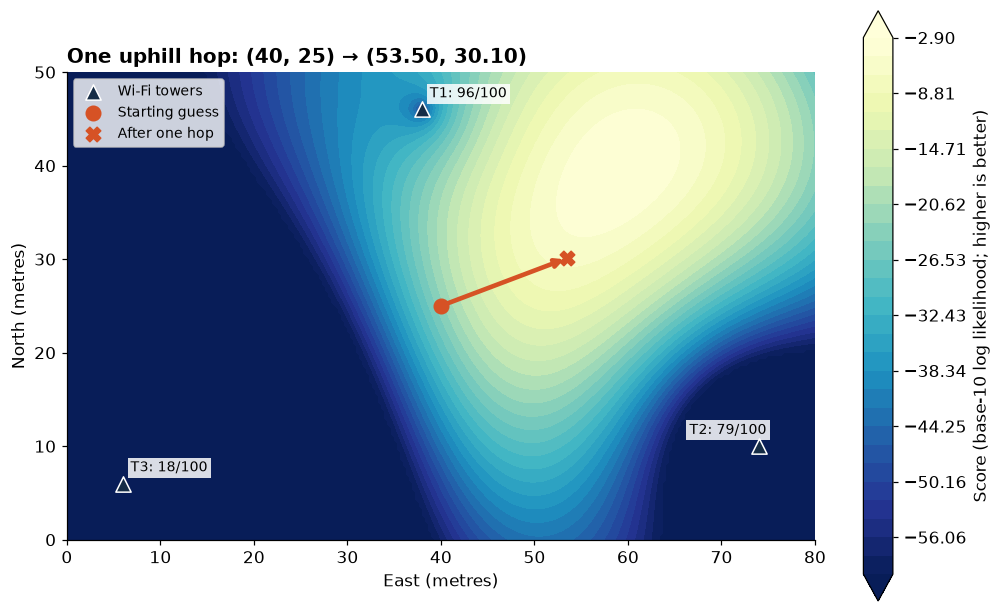

In [ ]:
# Reset the guess each time you run this cell.
position = torch.tensor([40., 25.], dtype=DTYPE, requires_grad=True)
current_score = score(position)
current_score.backward()  # Ask PyTorch for the slopes.
slope = position.grad.round(decimals=2)  # Match the section's rounding.

print(f'Starting score: {current_score.item():.2f}')
print(f'Uphill arrow: {slope[0].item():.2f} east, {slope[1].item():.2f} north')

step_size = 6
start = position.detach().numpy().copy()
with torch.no_grad():  # Moving the guess is not part of the scoring rule.
    position += step_size * slope  # PLUS means we climb uphill.

print(f'Hop: {step_size * slope[0].item():.2f} m east, {step_size * slope[1].item():.2f} m north')
print(f'New guess: ({position[0].item():.2f}, {position[1].item():.2f})')
print(f'New score: {score(position).item():.2f}')
plot_hop(start, position.detach().numpy())

**What to notice:** the arrow is **(2.25, 0.85)**. Multiplying by 6 gives a hop of **(13.50, 5.10) m**.
The guess becomes **(53.50, 30.10)** and the score improves from **−23.41 to −6.23**.

This is gradient **ascent**: we **add** the slope because a higher score is better.
The map shows the whole scoring landscape so we can understand the journey; the update itself only uses the slope at the current guess.

## Task 2: Repeat the climb
If the step size stays at 6, why might the hops get smaller?

The computer repeats the same recipe: **score → slope → hop**.
The next cell resets to (40, 25), so rerunning it always reproduces the same climb.

`position.grad = None` clears the previous slopes: PyTorch otherwise adds new gradients to old ones.
The loop has a limit of 100 hops as a safeguard; that limit is not a claim that we reached a top.

Hop     East    North     Score       Rounded slope
  0    40.00    25.00    -23.41      (2.25, 0.85)
  1    53.50    30.10     -6.23      (0.08, 0.61)
  2    53.98    33.76     -4.50      (0.25, 0.29)
  3    55.48    35.50     -3.73      (0.18, 0.21)
  4    56.56    36.76     -3.33      (0.13, 0.15)
  5    57.34    37.66     -3.12      (0.09, 0.11)
  6    57.88    38.32     -3.02      (0.07, 0.07)
  7    58.30    38.74     -2.97      (0.04, 0.05)
  8    58.54    39.04     -2.95      (0.03, 0.03)
  9    58.72    39.22     -2.95      (0.02, 0.02)
 10    58.84    39.34     -2.94      (0.01, 0.01)

Stopped: the proposed next hop is shorter than 0.10 m.
Final guess: (58.84, 39.34)
Distance from the actual phone: 1.77 m


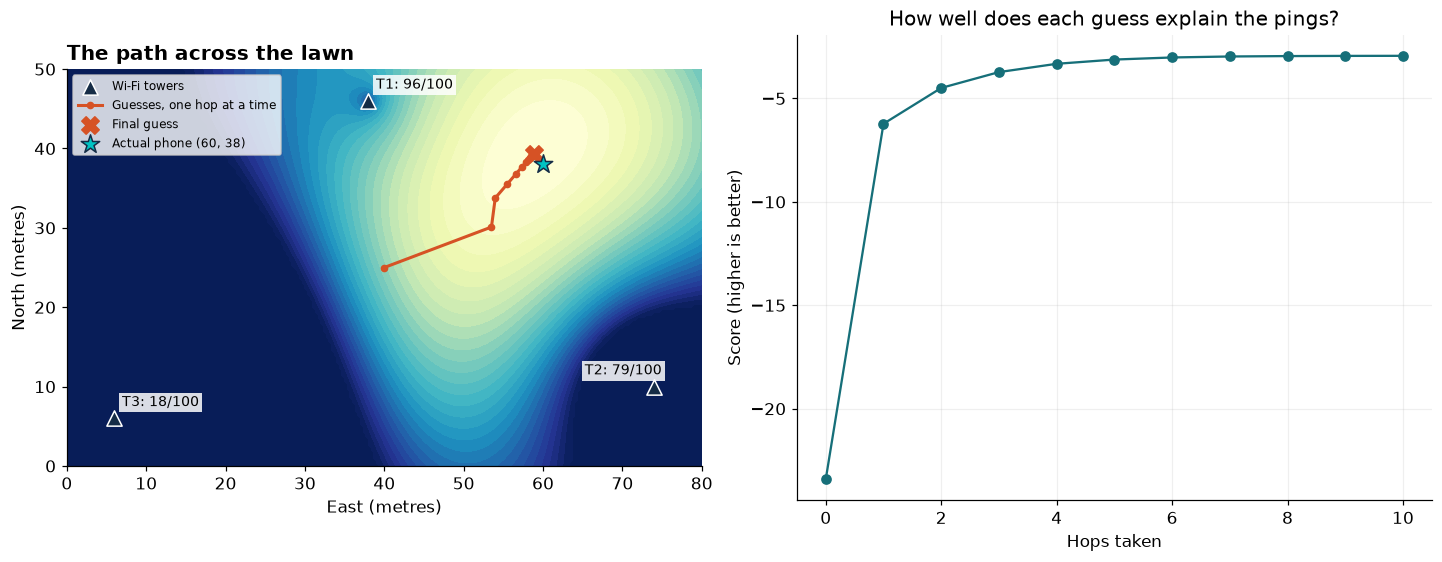

In [ ]:
def climb(start=(40., 25.), step_size=6, max_hops=100, verbose=True):
    position = torch.tensor(start, dtype=DTYPE, requires_grad=True)
    path, scores = [], []
    reason = 'Reached the hop limit; convergence is not established.'
    if verbose:
        print('Hop     East    North     Score       Rounded slope')

    for hop_number in range(max_hops + 1):
        position.grad = None
        current_score = score(position)
        current_score.backward()
        slope = position.grad.round(decimals=2)
        hop = step_size * slope
        path.append(position.detach().numpy().copy())
        scores.append(current_score.item())

        if verbose:
            print(f'{hop_number:3d}   {position[0].item():6.2f}   {position[1].item():6.2f}'
                  f'   {current_score.item():7.2f}      ({slope[0].item():.2f}, {slope[1].item():.2f})')

        if not torch.isfinite(current_score) or not torch.isfinite(hop).all():
            reason = 'Stopped: non-finite calculation. Try a smaller step size.'
            break
        if torch.linalg.vector_norm(hop).item() < 0.10:
            reason = 'Stopped: the proposed next hop is shorter than 0.10 m.'
            break
        if hop_number == max_hops:
            break
        with torch.no_grad():
            candidate = position + hop
            if not (0 <= candidate[0] <= 80 and 0 <= candidate[1] <= 50):
                reason = 'Stopped: the next hop would leave the lawn. Try a smaller step size.'
                break
            position += hop  # Gradient ASCENT.

    if verbose:
        print('\n' + reason)
    return np.array(path), np.array(scores), reason

path, scores, reason = climb()
plot_climb(path, scores)
error = np.linalg.norm(path[-1] - true_phone)
print(f'Final guess: ({path[-1, 0]:.2f}, {path[-1, 1]:.2f})')
print(f'Distance from the actual phone: {error:.2f} m')

### What happened?
- After **10 hops**, we reach **(58.84, 39.34)**, with score about **−2.94**, just as in section.
- The next rounded slope is **(0.01, 0.01)**. With step size 6, the next hop would be about **8.5 cm**, so we stop.
- The step size stayed fixed. The hops got smaller because the slopes got smaller.
- The real phone is at **(60, 38)**, about **1.77 m** from our final guess. The pings are random, so the best explanation of these particular counts need not be the exact true location.

Our stopping point is an approximation. The handout's finer grid puts the best spot near **(59.05, 39.50)**, about **0.26 m** away. A small gradient or hop does not, by itself, prove we have found the highest possible score.

**The connection to machine learning:** here the parameters are two coordinates. In larger models they can be many weights, but the core idea is the same: use the data to score parameters, calculate slopes, and update the parameters.

## Optional: change one number and predict
There is no coding assignment here. If you are curious, edit the numbers below and run just that cell again.

1. Keep the start at (40, 25), but change the step size from **6 to 1**. Does progress become slower?
2. Try **60**. The initial eastward hop alone would be **135 m**. The notebook reports that the next hop would leave the lawn and stops; it does not move the guess back onto the lawn automatically.
3. Restore **6**, then try another starting point such as **(70, 20)**. Does the journey change?

You may see decreases in score or a stopping message for some choices. An uphill arrow describes the slope **here**; it does not promise that every large jump will improve the score.

Stopped: the proposed next hop is shorter than 0.10 m.
Hops taken: 10
Last guess: (58.84, 39.34)
Last score: -2.94


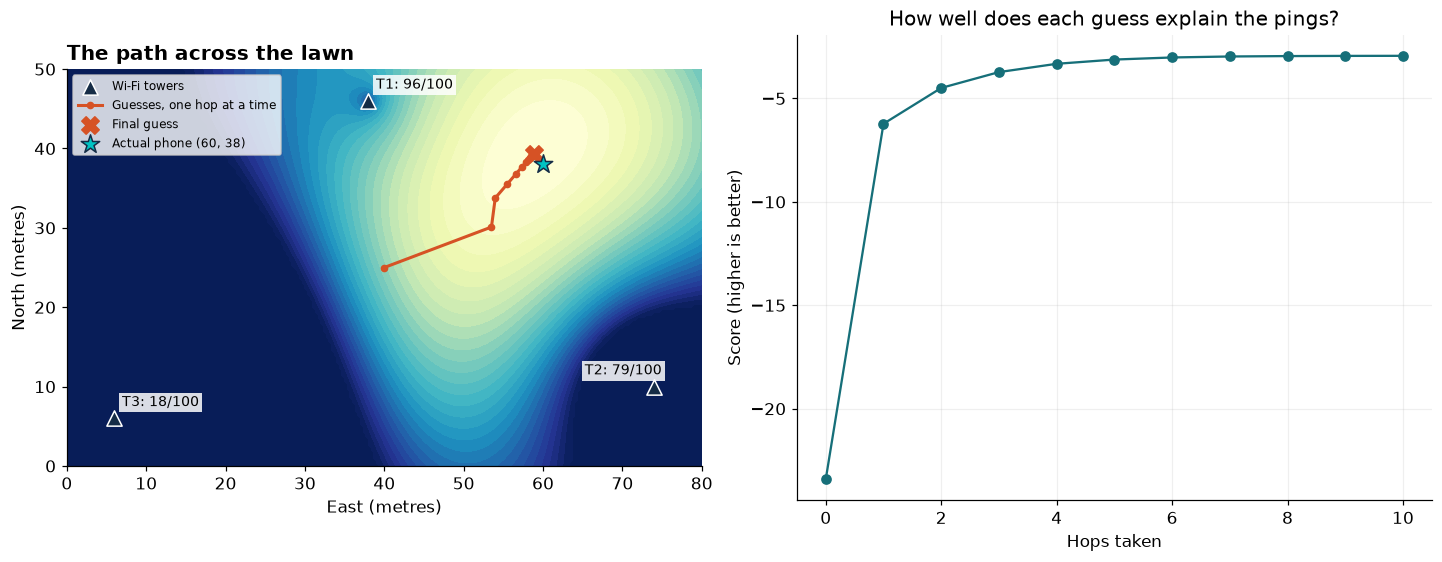

In [ ]:
# Change these three numbers if you want to explore.
start_east = 40.0
start_north = 25.0
step_size = 6.0

if not (0 <= start_east <= 80 and 0 <= start_north <= 50):
    print('Choose a starting point on the 80 m by 50 m lawn.')
elif step_size <= 0:
    print('Choose a positive step size for ascent.')
else:
    trial_path, trial_scores, message = climb(
        start=(start_east, start_north), step_size=step_size, verbose=False)
    plot_climb(trial_path, trial_scores)
    print(message)
    print(f'Hops taken: {len(trial_path)-1}')
    print(f'Last guess: ({trial_path[-1, 0]:.2f}, {trial_path[-1, 1]:.2f})')
    print(f'Last score: {trial_scores[-1]:.2f}')

## If you want to read the Python

| Python | Meaning here |
|---|---|
| `torch.tensor([40., 25.], ...)` | Store the east and north coordinates. |
| `requires_grad=True` | Ask PyTorch to track how the score depends on those coordinates. |
| `score(position)` | Evaluate how well this guess explains the observed pings. |
| `current_score.backward()` | Calculate the two slopes automatically. |
| `position.grad` | Read the uphill arrow. |
| `.round(decimals=2)` | Use the same rounded slopes as the section exercise. |
| `with torch.no_grad():` | Keep the coordinate update outside the slope calculation. |
| `position += step_size * slope` | Move uphill: new guess = old guess + step size × slope. |
| `position.grad = None` | Clear old slopes before calculating fresh ones. |

The setup includes the full binomial probability, including the combination term, so the displayed scores match section. It uses base-10 logs throughout. Rounding each slope is for matching the classroom arithmetic; typical optimization code keeps full precision.

### A note for readers who have seen PyTorch before
Many examples minimize a loss, so their updates use gradient descent. Here our score is something we want to **maximize**, and we explicitly add its gradient. PyTorch's `torch.optim.SGD` also supports `maximize=True`; a manual update makes the section's hop rule and rounding easier to see.

### Read more
- [PyTorch: automatic differentiation](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)
- [PyTorch: SGD and its maximize option](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD)
- [Google Colab runtime information](https://research.google.com/colaboratory/runtime-version-faq.html)

